# PyramidNet with two-branch weight averaging
Sheng Tao

This notebook executes the final model. Training curves are read from completed experiments; the official final test score (87.60%) was reported by the competition and is not computed from unavailable hidden labels.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from inference import load,predict,export
DATA=Path(os.environ.get('CIFAR_DATA',str(ROOT/'data')))
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
model,ck=load(ROOT/'artifacts/final.pt',DEVICE)
print('Device:',DEVICE,'PyTorch:',torch.__version__)
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Residual blocks:',len(model.blocks))
print('Checkpoint SHA256:',hashlib.sha256((ROOT/'artifacts/final.pt').read_bytes()).hexdigest())

Device: cuda PyTorch: 2.6.0+cu124
Trainable parameters: 4804512
Residual blocks: 54
Checkpoint SHA256: ada2fc2fbbc0310665312412ef01b8caec98a3a3c76e9c237c83f1580d6ae9ca


## Training evidence
A shared 400-epoch model supplies the EMA initialization for two 20-epoch branches. Both branches use 45,000 training images. Curves below come from saved logs, not a new training run.

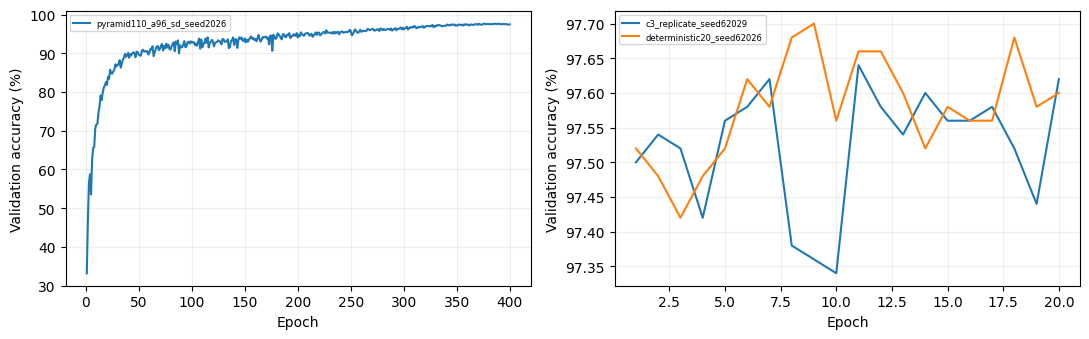

In [2]:
import csv
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for folder in sorted((ROOT/'results/evidence').iterdir()):
 rows=list(csv.DictReader((folder/'metrics.csv').open()))
 ax=axes[0 if len(rows)==400 else 1]
 ax.plot([int(r['epoch']) for r in rows],[100*float(r['raw_val_accuracy']) for r in rows],label=folder.name)
for ax in axes:
 ax.set(xlabel='Epoch',ylabel='Validation accuracy (%)');ax.legend(fontsize=6);ax.grid(alpha=.2)
plt.tight_layout();plt.show()

## Executed validation
The development split has been reused during model selection. Its accuracy is not an unbiased estimate of final test accuracy. The following cell evaluates all 5,000 held-out images using the exact 50-view policy.

In [3]:
split=np.load(ROOT/'results/split_seed2026.npz')
assert len(split['train'])==45000 and len(split['val'])==5000
assert not np.intersect1d(split['train'],split['val']).size
x=np.load(DATA/'cache/train.npy',mmap_mode='r')[split['val']]
y=np.load(DATA/'cache/labels.npy')[split['val']]
p=predict(model,ck,x,DEVICE)
correct=int((p.argmax(1)==y).sum())
nll=float(-np.log(p[np.arange(len(y)),y]).mean())
print({'correct':correct,'count':len(y),'accuracy':correct/len(y),'nll':nll})
assert correct==4895

{'correct': 4895, 'count': 5000, 'accuracy': 0.979, 'nll': 0.07172156870365143}


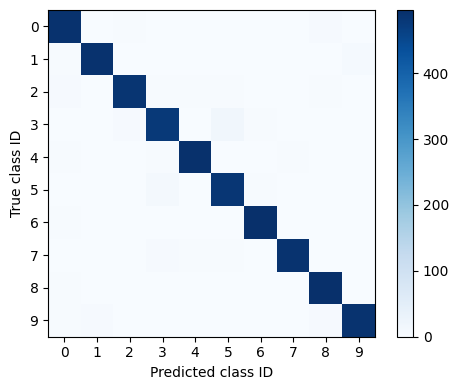

Per-class accuracy: [0.982 0.984 0.972 0.956 0.986 0.968 0.992 0.98  0.992 0.978]


In [4]:
confusion=np.zeros((10,10),dtype=int)
np.add.at(confusion,(y,p.argmax(1)),1)
fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(confusion,cmap='Blues');fig.colorbar(im,ax=ax)
ax.set(xlabel='Predicted class ID',ylabel='True class ID',xticks=range(10),yticks=range(10));plt.tight_layout();plt.show()
print('Per-class accuracy:',confusion.diagonal()/confusion.sum(1))

## Executed submission reproduction
The official test images are used only for inference. No hidden labels are read. This cell checks the complete prediction file against the originally submitted file hash.

In [5]:
checks=export(model,ck,DATA,ROOT/'outputs/notebook_submission.csv',DEVICE)
print(checks)
assert checks['sha256']=='9ad0bec166bb59bda06feb1e9be1922005bea2c8060fd790836e23e8c7386e12'

{'rows': 2000, 'sha256': '9ad0bec166bb59bda06feb1e9be1922005bea2c8060fd790836e23e8c7386e12', 'parameters': 4804512}


## Reproduction
Use the training commands in README to train the 400-epoch base and two 20-epoch branches. The notebook intentionally does not repeat that training. Final inference uses one 4,804,512-parameter model; 50 views increase inference computation, not the parameter count. Small development-set gains after repeated selection are not evidence of statistical significance.